In [2]:
pip install PyMPDATA

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [PyMPDATA]


In [2]:
import PyMPDATA
print(PyMPDATA.__file__)
print("\n")
import numba
print(numba.__file__)
print(numba.version_info)

import numpy as np
import matplotlib.pyplot as plt


/usr/local/lib/python3.13/dist-packages/PyMPDATA/__init__.py


/usr/local/lib/python3.13/dist-packages/numba/__init__.py
version_info(major=0, minor=61, patch=2, short=(0, 61), full=(0, 61, 2), string='0.61.2', tuple=('0', '61', '2'), git_revision=None)


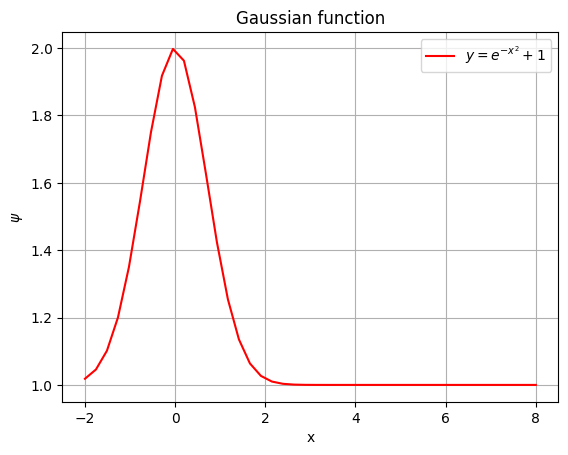

In [18]:
x = np.linspace(-2, 8, 42)
psi = np.exp(-x**2)+1
plt.plot(x, psi, 'r-', label=r"$y=e^{-x^2}+1$")
plt.grid()
plt.xlabel("x")
plt.ylabel(r"$\psi$")
plt.title("Gaussian function")
plt.legend()
plt.show()



In [23]:
from PyMPDATA import Solver, ScalarField, VectorField, Options, boundary_conditions, Stepper


common = {
    'halo': (options := Options(nonoscillatory=True)).n_halo,
    'boundary_conditions': (boundary_conditions.Periodic(),)
}

advector = VectorField(**common, data=(np.full(x.size+1, 1/4),)) #1/4 -> Courant number
advectee = ScalarField(**common, data=psi)


solver = Solver(advector=advector, advectee=advectee, stepper=Stepper(n_dims=1, options=options))
solver.advance(n_steps=100)



10573.79

/tmp/ipykernel_10972/535491850.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


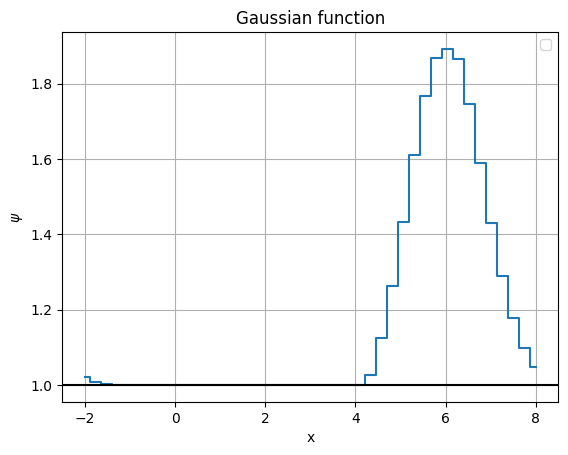

In [24]:
plt.step(x, solver.advectee.get(), where='mid')
plt.grid()
plt.xlabel("x")
plt.ylabel(r"$\psi$")
plt.axhline(1, color='black')
plt.title("Gaussian function")
plt.legend()
plt.show()
